<a href="https://colab.research.google.com/github/LanovenkoOleh/ML/blob/main/%D0%9B%D0%A0_11_%D0%9C%D0%9D_%D0%A2%D0%B5%D1%81%D1%82%D0%BE%D0%B2%D0%B5_%D0%B7%D0%B0%D0%B2%D0%B4%D0%B0%D0%BD%D0%BD%D1%8F_%D0%B4%D0%B6%D1%83%D0%BD%D1%96%D0%BE%D1%80_%D0%9B%D0%B0%D0%BD%D0%BE%D0%B2%D0%B5%D0%BD%D0%BA%D0%BE_%D0%A4%D0%86%D0%A2_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №11
## Прогнозування відтоку клієнтів методами машинного навчання

**Дисципліна:** Машинне навчання  
**Виконав:** Лановенко Олег  
**Група:** ФІТ 3-10

**Мета:** проаналізувати дані клієнтів, підготувати їх, навчити класичні моделі класифікації, підібрати параметри, порівняти метрики та отримати прогноз для нового клієнта.

## 1. Завантаження бібліотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, ConfusionMatrixDisplay

## 2. Завантаження набору даних

Джерело: [Telco Customer Churn (Kaggle)](https://www.kaggle.com/datasets/blastchar/telco-customer-churn). Файл: `WA_Fn-UseC_-Telco-Customer-Churn.csv`. Для запуску в Colab використаємо відкриту копію цього CSV з GitHub, тому завантажувати вручну нічого не потрібно. За потреби файл можна завантажити з Kaggle та прочитати через `pd.read_csv`.

In [2]:
url = 'https://raw.githubusercontent.com/rstudio/keras-customer-churn/master/data/WA_Fn-UseC_-Telco-Customer-Churn.csv'
df = pd.read_csv(url)
print('Розмір даних:', df.shape)
display(df.head())

Розмір даних: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Початковий аналіз даних

In [3]:
df.info()
print('Пропущені значення:')
print(df.isnull().sum())
print('Розподіл цільової ознаки:')
print(df['Churn'].value_counts())
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


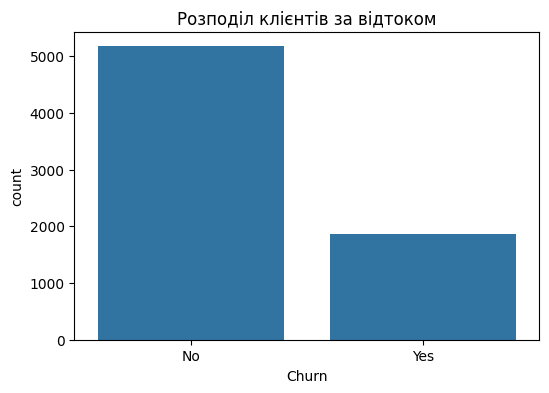

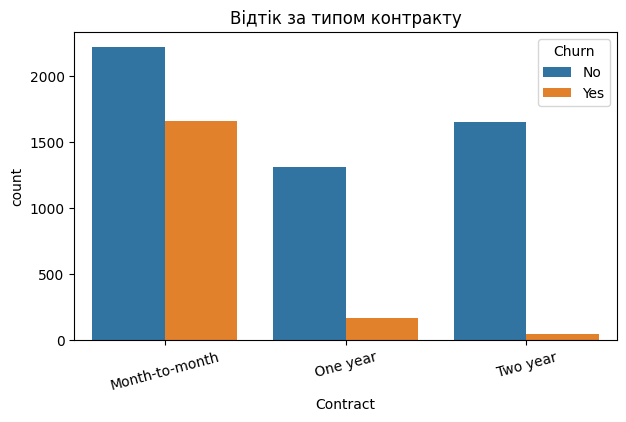

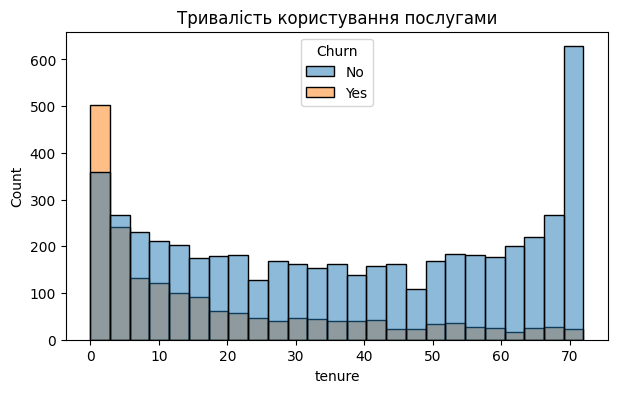

In [4]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Churn')
plt.title('Розподіл клієнтів за відтоком')
plt.show()

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='Contract', hue='Churn')
plt.title('Відтік за типом контракту')
plt.xticks(rotation=15)
plt.show()

plt.figure(figsize=(7, 4))
sns.histplot(data=df, x='tenure', hue='Churn', bins=25)
plt.title('Тривалість користування послугами')
plt.show()

## 4. Підготовка даних

Прибираємо ідентифікатор, перетворюємо `TotalCharges` на число та `Churn` на 0/1. Числові ознаки заповнюємо медіаною та масштабуємо, категоріальні — заповнюємо найчастішим значенням і кодуємо OneHotEncoder. Усі перетворення навчаються лише на навчальних даних.

In [5]:
df = df.drop(columns=['customerID'])
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})

X = df.drop(columns=['Churn'])
y = df['Churn']

num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()

print('Числові ознаки:', num_cols)
print('Категоріальні ознаки:', cat_cols)
print('Пропуски:', X.isnull().sum().sum())

Числові ознаки: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Категоріальні ознаки: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Пропуски: 11


## 5. Розділення на навчальну і тестову вибірки

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

print('Навчальна вибірка:', X_train.shape)
print('Тестова вибірка:', X_test.shape)

Навчальна вибірка: (5634, 19)
Тестова вибірка: (1409, 19)


## 6. Створення та навчання класичних моделей

In [7]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42)
}

results = []
for name, model in models.items():
    pipeline = Pipeline([('preprocessor', preprocessor), ('model', model)])
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)
    results.append([name, accuracy_score(y_test, pred), precision_score(y_test, pred),
                    recall_score(y_test, pred), f1_score(y_test, pred)])

results_df = pd.DataFrame(results, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1'])
display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040
1,Decision Tree,0.7289,0.4896,0.5053,0.4974
2,Random Forest,0.7779,0.6034,0.4759,0.5321


## 7. Порівняння результатів

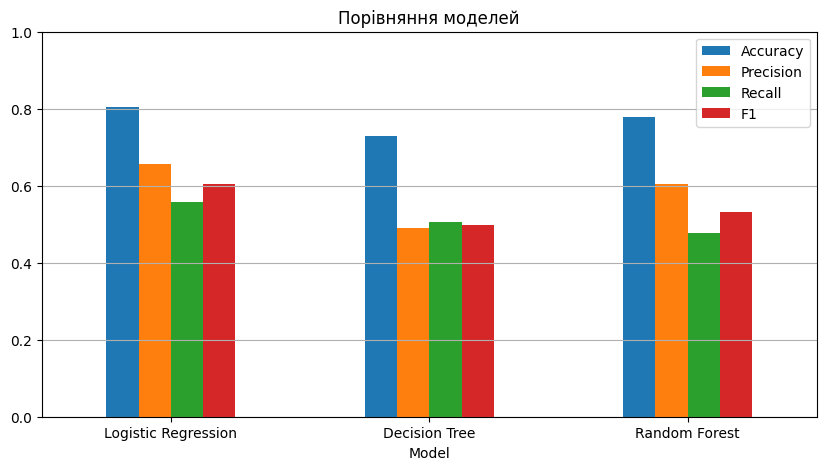

In [8]:
results_df.set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1']].plot(kind='bar', figsize=(10, 5))
plt.title('Порівняння моделей')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

## 8. Підбір гіперпараметрів

Підбираємо параметри трьох моделей за допомогою GridSearchCV з трикратною кросвалідацією. Основна метрика — **F1** для класу відтоку (`Churn = 1`). Тестові дані під час підбору не використовуються.

In [9]:
param_grids = {
    'Logistic Regression': {'model__C': [0.1, 1, 10]},
    'Decision Tree': {'model__max_depth': [3, 5, 10], 'model__min_samples_split': [2, 10]},
    'Random Forest': {'model__n_estimators': [100, 200], 'model__max_depth': [5, 10, None]}
}

grid_results = {}
for name, model in models.items():
    pipeline = Pipeline([('preprocessor', preprocessor), ('model', model)])
    grid = GridSearchCV(pipeline, param_grids[name], cv=3, scoring='f1', n_jobs=-1)
    grid.fit(X_train, y_train)
    grid_results[name] = grid
    print(name)
    print('Найкращі параметри:', grid.best_params_)
    print('CV F1:', round(grid.best_score_, 4))
    print()

Logistic Regression
Найкращі параметри: {'model__C': 10}
CV F1: 0.5995

Decision Tree
Найкращі параметри: {'model__max_depth': 5, 'model__min_samples_split': 2}
CV F1: 0.5565

Random Forest
Найкращі параметри: {'model__max_depth': 10, 'model__n_estimators': 100}
CV F1: 0.5774



## 9. Вибір найкращої моделі

Модель вибирається за F1 на кросвалідації. Після цього один раз оцінюємо обрану модель на тестових даних.

In [10]:
cv_results = pd.DataFrame({
    'Model': list(grid_results.keys()),
    'CV F1': [grid.best_score_ for grid in grid_results.values()]
}).sort_values('CV F1', ascending=False)
display(cv_results.round(4))

best_model_name = cv_results.iloc[0]['Model']
best_model = grid_results[best_model_name].best_estimator_
print('Найкраща модель:', best_model_name)
print('Її параметри:', grid_results[best_model_name].best_params_)

,Model,CV F1
0,Logistic Regression,0.5995
2,Random Forest,0.5774
1,Decision Tree,0.5565


Найкраща модель: Logistic Regression
Її параметри: {'model__C': 10}


## 10. Фінальні метрики найкращої моделі

Accuracy: 0.8055
Precision: 0.6572
Recall: 0.5588
F1: 0.604

              precision    recall  f1-score   support

  Залишиться       0.85      0.89      0.87      1035
        Піде       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



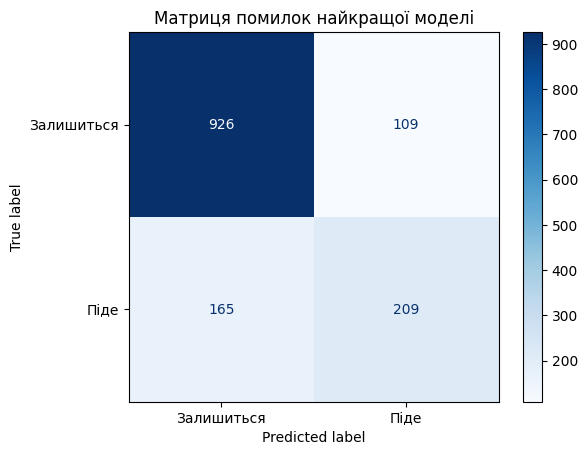

In [11]:
y_pred = best_model.predict(X_test)
print('Accuracy:', round(accuracy_score(y_test, y_pred), 4))
print('Precision:', round(precision_score(y_test, y_pred), 4))
print('Recall:', round(recall_score(y_test, y_pred), 4))
print('F1:', round(f1_score(y_test, y_pred), 4))
print()
print(classification_report(y_test, y_pred, target_names=['Залишиться', 'Піде']))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['Залишиться', 'Піде'], cmap='Blues')
plt.title('Матриця помилок найкращої моделі')
plt.show()

## 11. Прогноз для нового клієнта

Нижче вводимо значення характеристик клієнта. Для простоти спочатку беремо типовий запис із набору даних та змінюємо його параметри.

In [12]:
client_data = X.iloc[0].to_dict()
client_data.update({
    'gender': 'Female',
    'SeniorCitizen': 0,
    'tenure': 3,
    'Contract': 'Month-to-month',
    'InternetService': 'Fiber optic',
    'MonthlyCharges': 85.0,
    'TotalCharges': 255.0,
    'PaymentMethod': 'Electronic check'
})

new_client = pd.DataFrame([client_data])
display(new_client.T)

,0
gender,Female
SeniorCitizen,0
Partner,Yes
Dependents,No
tenure,3
PhoneService,No
MultipleLines,No phone service
InternetService,Fiber optic
OnlineSecurity,No
OnlineBackup,Yes


In [13]:
prediction = best_model.predict(new_client)[0]
probability = best_model.predict_proba(new_client)[0][1]

if prediction == 1:
    print('Прогноз: клієнт піде')
else:
    print('Прогноз: клієнт залишиться')

print('Ймовірність відтоку:', round(probability * 100, 2), '%')

Прогноз: клієнт залишиться
Ймовірність відтоку: 31.66 %


## 12. Висновок

У ході лабораторної роботи було реалізовано задачу прогнозування відтоку клієнтів на основі набору даних Telco Customer Churn, що містить 7043 записи. Проведено початковий аналіз даних, обробку пропущених значень, кодування категоріальних ознак та масштабування числових даних.

Для прогнозування було використано три класичні моделі машинного навчання: Logistic Regression, Decision Tree та Random Forest. За результатами початкового порівняння найкращі показники отримала логістична регресія з Accuracy 80,55%, Precision 65,72%, Recall 55,88% та F1 0,6040.

Після підбору гіперпараметрів за допомогою GridSearchCV найкращою моделлю залишилася Logistic Regression з параметром C = 10 та результатом F1 = 0,5995 на кросвалідації. На тестовій вибірці модель отримала Accuracy 80,55% та F1 0,6040, що підтверджує її ефективність для поставленої задачі.

На завершальному етапі було виконано прогноз для нового клієнта із заданими характеристиками. Модель визначила, що клієнт залишиться, оцінивши ймовірність його відтоку в 31,66%.
